## Step 1 - Install Packages

In [1]:
!pip install scikit-learn==1.6.0 streamlit==1.30.0 pandas==2.0.3 numpy==1.26.4 matplotlib==3.8.2 seaborn plotly joblib

  Using cached scikit_learn-1.6.0-cp313-cp313-win_amd64.whl.metadata (15 kB)
  Using cached streamlit-1.30.0-py2.py3-none-any.whl.metadata (8.2 kB)
  Using cached pandas-2.0.3.tar.gz (5.3 MB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'


  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [23 lines of output]
      Traceback (most recent call last):
        File "C:\Users\Fatima\AppData\Local\Programs\Python\Python313\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 353, in <module>
          main()
          ~~~~^^
        File "C:\Users\Fatima\AppData\Local\Programs\Python\Python313\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 335, in main
          json_out['return_val'] = hook(**hook_input['kwargs'])
                                   ~~~~^^^^^^^^^^^^^^^^^^^^^^^^
        File "C:\Users\Fatima\AppData\Local\Programs\Python\Python313\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 118, in get_requires_for_build_wheel
          return hook(config_settings)
        File "C:\Users\Fatima\AppData\Local\Temp\pip-build-env-u9stmihv\overlay\Lib\site-p

## Step 2 - Import Liabraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import joblib

from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Step 3 - Load the Dataset

In [3]:
df = pd.read_csv("global_ecommerce_extreme_regression_dataset.csv")


C:\Users\Fatima\AppData\Local\Temp\ipykernel_31244\1893476986.py:1: DtypeWarning: Columns (0: avg_pages_viewed) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("global_ecommerce_extreme_regression_dataset.csv")


## Step 4 - Exporatory Data Analysis(EDA) - Before Cleaning

In [4]:
print("="*50)
print("ORIGINAL DATASET OVERVIEW")
print("="*50)
print(f"Initial Rows: {df.shape[0]:,}")
print(f"Initial Columns: {df.shape[1]}")
print(f"Duplicate Rows: {df.duplicated().sum():,}")

print("\n" + "="*50)
print("MISSING VALUES (Top 5 Columns)")
print("="*50)
print(df.isnull().sum().sort_values(ascending=False).head(5))

print("\n" + "="*50)
print("TARGET VARIABLE STATISTICS (future_customer_spend_90d)")
print("="*50)
# We use the exact cleaning logic from your Step 4 to get accurate stats
target_col = 'future_customer_spend_90d'
s = pd.to_numeric(
    df[target_col].astype(str).str.replace(r'[^0-9.-]', '', regex=True),
    errors='coerce'
).dropna()

print(f"Minimum Spend: ${s.min():,.2f}")
print(f"Median Spend:  ${s.median():,.2f}")
print(f"95th Percentile: ${s.quantile(0.95):,.2f}")
print(f"Maximum Spend: ${s.max():,.2f}")

print("\n" + "="*50)
print("DESCRIPTIVE STATISTICS TABLE (df.describe)")
print("="*50)
# This generates the table you should screenshot for your report
# (Using .T to transpose it so it's easier to read in a wide format)
display(df.describe().T) 

ORIGINAL DATASET OVERVIEW
Initial Rows: 360,500
Initial Columns: 89
Duplicate Rows: 10,499

MISSING VALUES (Top 5 Columns)
email_open_rate    44166
age                 5712
customer_id            0
region                 0
country_code           0
dtype: int64

TARGET VARIABLE STATISTICS (future_customer_spend_90d)
Minimum Spend: $0.00
Median Spend:  $137.84
95th Percentile: $574.10
Maximum Spend: $72,490.81

DESCRIPTIVE STATISTICS TABLE (df.describe)


,count,mean,std,min,25%,50%,75%,max
customer_id,360500.0,175005.217675,101005.732249,0.000000,87569.750000,174990.500000,262452.250000,349999.000000
discount_usage_rate,360500.0,0.332809,0.200867,0.000032,0.170583,0.306490,0.470441,0.987503
email_open_rate,316334.0,0.333365,0.178034,0.000105,0.193839,0.313976,0.454056,0.966821
avg_review_score,360500.0,4.001461,0.699933,0.726419,3.529818,4.000119,4.474548,7.372453
marketing_id,360500.0,24948.534985,14436.115394,0.000000,12421.000000,24917.000000,37481.000000,49999.000000
...,...,...,...,...,...,...,...,...
noise_feature_56,360500.0,0.001715,0.998728,-4.240909,-0.671269,0.000838,0.674173,4.431925
noise_feature_57,360500.0,-0.000304,0.999353,-4.717793,-0.674689,0.000199,0.673439,4.446540
noise_feature_58,360500.0,0.003389,0.998842,-4.494858,-0.672267,0.001094,0.676429,4.673959
noise_feature_59,360500.0,0.001242,1.001052,-4.593010,-0.674554,0.002184,0.676958,4.816019


Min: 0.0 Median: 137.835 95th pct: 574.1004999999999 Max: 72490.81


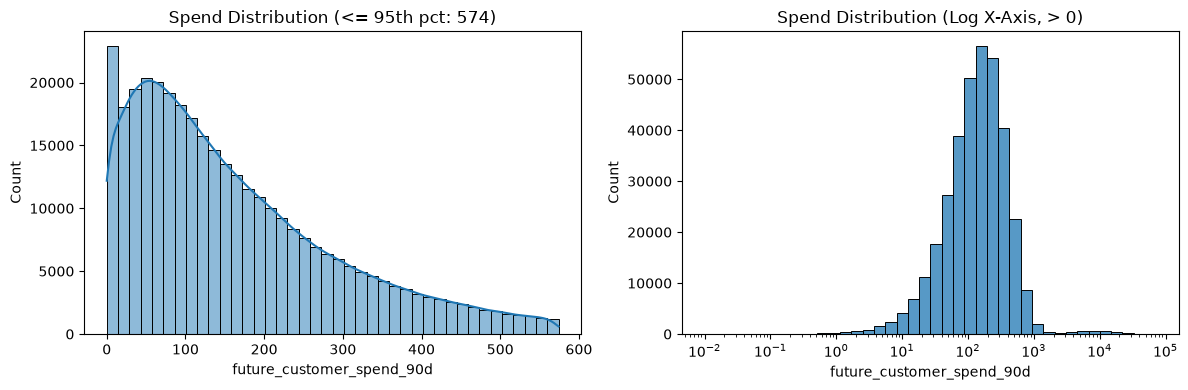

In [8]:
target_col = 'future_customer_spend_90d'
s = pd.to_numeric(
    df[target_col].astype(str).str.replace(r'[^0-9.-]', '', regex=True),
    errors='coerce'
).dropna()

print("Min:", s.min(), "Median:", s.median(), "95th pct:", s.quantile(0.95), "Max:", s.max())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 1. Zoomed in to the bulk of the data (e.g., up to 95th percentile)
cap = s.quantile(0.95)
sns.histplot(s[s <= cap], bins=40, kde=True, ax=axes[0])
axes[0].set_title(f"Spend Distribution (<= 95th pct: {cap:,.0f})")

# 2. Log scale (for positive values) to reveal heavy tail across orders of magnitude
sns.histplot(s[s > 0], bins=40, log_scale=True, ax=axes[1])
axes[1].set_title("Spend Distribution (Log X-Axis, > 0)")

plt.tight_layout()
plt.savefig('results/figures/target_distribution_zoomed.png', dpi=150)
plt.show()

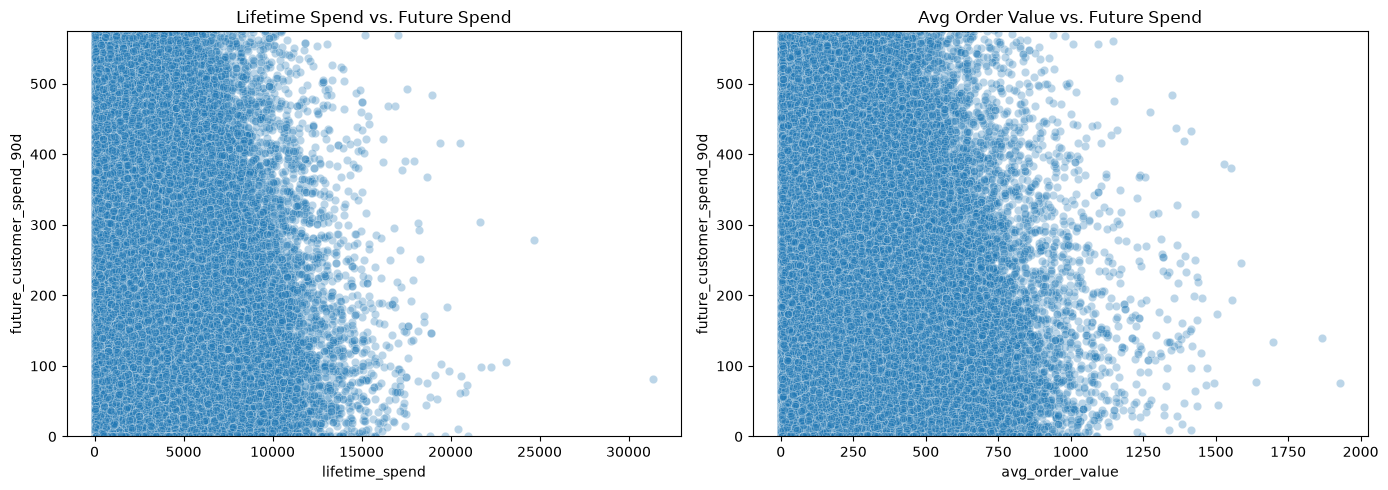

In [10]:
# Scatter Plot:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter 1: Lifetime Spend vs Target
# Create a plotting-ready copy if the cleaning cell has not been run
if 'df_new' not in globals():
    df_new = df.copy()

for col in ['lifetime_spend', 'avg_order_value', 'future_customer_spend_90d']:
    if col in df_new.columns:
        df_new[col] = pd.to_numeric(
            df_new[col].astype(str).str.replace(r'[$,]', '', regex=True),
            errors='coerce'
        )

sns.scatterplot(
    data=df_new,
    x='lifetime_spend',
    y='future_customer_spend_90d',
    alpha=0.3,
    ax=axes[0]
)
axes[0].set_title("Lifetime Spend vs. Future Spend")
axes[0].set_ylim(0, df_new['future_customer_spend_90d'].quantile(0.95)) # Cap y-axis for visibility

# Scatter 2: Avg Order Value vs Target
sns.scatterplot(data=df_new, x='avg_order_value', y='future_customer_spend_90d', alpha=0.3, ax=axes[1])
axes[1].set_title("Avg Order Value vs. Future Spend")
axes[1].set_ylim(0, df_new['future_customer_spend_90d'].quantile(0.95))

plt.tight_layout()
plt.savefig('results/figures/scatter_features_vs_target.png', dpi=150)
plt.show()

## Step 5 — Copy data, remove noise columns, clean issues, and impute missing values

In [11]:
# Step 5: Copy data, remove noise columns, clean issues, and impute missing values
df_new = df.copy()

# 1. Standardize column names (remove spaces, lowercase)
df_new.columns = df_new.columns.str.strip().str.lower()

# 2. Remove noise_feature_* columns
noise_cols = [c for c in df_new.columns if c.startswith('noise_feature')]
df_new = df_new.drop(columns=noise_cols)

# 3. Convert all "missing" tokens to real NaN and standardize text
missing_values = [
    '?', '??', 'n/a', 'na', 'null', 'none',
    'unknown', 'missing', 'error', '-', '--', '', ' '
]
df_new = df_new.replace(missing_values, np.nan)

# Strip spaces and lowercase all text columns
object_cols = df_new.select_dtypes(include='object').columns
for col in object_cols:
    df_new[col] = df_new[col].astype(str).str.strip().str.lower()

# astype(str) turns NaN into the text 'nan', so convert it back
df_new = df_new.replace(['nan', 'none', ''], np.nan)

# 4. Standardize country codes, device preference, and traffic source
country_mapping = {
    'us': 'usa',
    'u.s.': 'usa',
    'u.s.a.': 'usa',
    'united states': 'usa',
    'united states of america': 'usa',
    'u.k.': 'uk',
    'great britain': 'uk',
    'britain': 'uk',
    'u.a.e.': 'uae',
    'united arab emirates': 'uae'
}
if 'country_code' in df_new.columns:
    df_new['country_code'] = df_new['country_code'].replace(country_mapping)

if 'device_preference' in df_new.columns:
    df_new['device_preference'] = df_new['device_preference'].replace({
        'mobile': 'mobile',
        'desktop': 'desktop',
        'tablet': 'tablet'
    })

if 'traffic_source' in df_new.columns:
    traffic_mapping = {
        'organic': 'organic',
        'email': 'email',
        'affiliate': 'affiliate',
        'social': 'social',
        'ads': 'ads'
    }
    df_new['traffic_source'] = df_new['traffic_source'].replace(traffic_mapping)

# 5. Convert text values to numbers
if 'is_active' in df_new.columns:
    df_new['is_active'] = df_new['is_active'].replace({
        'yes': 1, 'y': 1, 'true': 1,
        'no': 0, 'n': 0, 'false': 0
    })

if 'loyalty_score' in df_new.columns:
    df_new['loyalty_score'] = df_new['loyalty_score'].replace({
        'low': 0.33,
        'medium': 0.66,
        'high': 1.00
    })

# 'many' is not a real number, so treat it as missing
if 'avg_pages_viewed' in df_new.columns:
    df_new['avg_pages_viewed'] = df_new['avg_pages_viewed'].replace({
        'many': np.nan
    })

# 6. Remove currency symbols and commas from money columns
money_columns = [
    'credit_limit',
    'avg_order_value',
    'lifetime_spend',
    'future_customer_spend_90d'
]
for col in money_columns:
    if col in df_new.columns:
        df_new[col] = (
            df_new[col]
            .astype(str)
            .str.replace('$', '', regex=False)
            .str.replace(',', '', regex=False)
            .str.strip()
        )

# Convert all numeric columns to numbers (invalid values become NaN)
numeric_columns = [
    'age',
    'loyalty_score',
    'discount_usage',
    'discount_usage_rate',
    'email_open_rate',
    'avg_review_score',
    'credit_limit',
    'avg_order_value',
    'lifetime_spend',
    'is_active',
    'marketing_id',
    'avg_session_duration',
    'avg_cart_additions',
    'avg_pages_viewed',
    'bounce_rate',
    'num_sessions_last_30d',
    'num_transactions',
    'average_income',
    'urban_ratio',
    'internet_penetration',
    'future_customer_spend_90d'
]
for col in numeric_columns:
    if col in df_new.columns:
        df_new[col] = pd.to_numeric(df_new[col], errors='coerce')

# 7. Drop rows with missing target, then remove duplicate rows
df_new = df_new.dropna(subset=['future_customer_spend_90d'])
df_new = df_new.drop_duplicates().reset_index(drop=True)

# 8. Fill ALL remaining missing values
# Numeric columns -> replace with the column mean
num_cols = df_new.select_dtypes(include=[np.number]).columns
df_new[num_cols] = df_new[num_cols].fillna(df_new[num_cols].mean())

# Text columns -> replace with the most frequent value (mean doesn't work for text)
cat_cols = df_new.select_dtypes(include=['object', 'category']).columns
for col in cat_cols:
    if df_new[col].isnull().any():
        df_new[col] = df_new[col].fillna(df_new[col].mode()[0])

# Safety net: if a column was entirely empty, fill any leftovers with 0
df_new = df_new.fillna(0)

# 9. Check the results
print("Removed noise columns:", len(noise_cols))
print("Cleaned shape:", df_new.shape)
print("Remaining duplicates:", df_new.duplicated().sum())
print("Remaining missing values:\n", df_new.isnull().sum()[df_new.isnull().sum() > 0])

# 10. Save the cleaned dataset
df_new.to_csv('cleaned_global_ecommerce_dataset.csv', index=False)
df_new.head()

C:\Users\Fatima\AppData\Local\Temp\ipykernel_31244\1586532311.py:19: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  object_cols = df_new.select_dtypes(include='object').columns
C:\Users\Fatima\AppData\Local\Temp\ipykernel_31244\1586532311.py:134: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/

Removed noise columns: 60
Cleaned shape: (350000, 29)
Remaining duplicates: 0
Remaining missing values:
 Series([], dtype: int64)


,customer_id,age,country_code,region,signup_date,loyalty_score,discount_usage_rate,email_open_rate,avg_review_score,customer_tier,...,avg_cart_additions,avg_pages_viewed,bounce_rate,num_sessions_last_30d,num_transactions,average_income,urban_ratio,internet_penetration,region_tier,future_customer_spend_90d
0,182994,43.0,au,region_95,2022-01-26,0.3461,0.313795,0.618761,5.066010,bronze,...,5,10.0,0.231956,8,3,30729.701037,0.480949,0.618679,tier3,114.18
1,229191,52.0,in,region_62,2023-07-14,0.0038,0.323821,0.607257,3.314194,diamond,...,0,5.0,0.464669,4,5,37873.300520,0.679706,0.588395,tier2,87.21
2,242964,27.0,usa,region_145,2022-06-22,0.2633,0.541580,0.259109,3.542250,gold,...,2,7.0,0.324568,3,3,75636.457436,0.538404,0.510991,tier1,132.28
3,306869,59.0,de,region_120,2021-12-15,0.2405,0.168623,0.534019,4.078036,platinum,...,1,11.0,0.206675,5,5,75820.638941,0.322021,0.531922,tier3,160.50
4,342915,63.0,fr,region_31,2023-06-07,0.2479,0.236642,0.432682,3.834070,silver,...,2,7.0,0.181683,7,5,97045.563690,0.692288,0.566294,tier3,574.72


In [12]:
# --- NEW FEATURE ENGINEERING ---

# 1. Average Spend Per Transaction
df_new['avg_spend_per_transaction'] = df_new['lifetime_spend'] / (df_new['num_transactions'] + 1)

# 2. Cart Conversion Rate (Additions per Page Viewed)
df_new['cart_conversion_rate'] = df_new['avg_cart_additions'] / (df_new['avg_pages_viewed'] + 1)

# 3. Credit Utilization Ratio (How much of their limit they use)
df_new['credit_utilization_ratio'] = df_new['lifetime_spend'] / (df_new['credit_limit'] + 1)

print("3 new features created successfully!")

3 new features created successfully!


## Step 6 - Separate input features and target

In [13]:
# Take a reproducible sample from cleaned df_new for faster modeling
df_sample = df_new.sample(n=20000, random_state=42).reset_index(drop=True)
print("Sample shape:", df_sample.shape)

target_col = 'future_customer_spend_90d'
drop_cols = {target_col, 'customer_id', 'referral_code', 'signup_date'}

feature_cols = [
    c for c in df_sample.columns
    if c not in drop_cols and not c.startswith('noise_feature')
]

cat_features = [
    c for c in feature_cols
    if df_sample[c].dtype == 'object' or str(df_sample[c].dtype) == 'category' or str(df_sample[c].dtype) == 'str'
]
num_features = [c for c in feature_cols if c not in cat_features]

print("Numeric features:", len(num_features), num_features)
print("Categorical features:", len(cat_features), cat_features)

X = df_sample[num_features + cat_features]
y = df_sample[target_col]

Sample shape: (20000, 32)
Numeric features: 22 ['age', 'loyalty_score', 'discount_usage_rate', 'email_open_rate', 'avg_review_score', 'credit_limit', 'avg_order_value', 'lifetime_spend', 'is_active', 'marketing_id', 'avg_session_duration', 'avg_cart_additions', 'avg_pages_viewed', 'bounce_rate', 'num_sessions_last_30d', 'num_transactions', 'average_income', 'urban_ratio', 'internet_penetration', 'avg_spend_per_transaction', 'cart_conversion_rate', 'credit_utilization_ratio']
Categorical features: 6 ['country_code', 'region', 'customer_tier', 'device_preference', 'traffic_source', 'region_tier']


## Step 7 - Train / Test split

In [14]:
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Step 8 — Create preprocessing pipelines


In [15]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler(with_mean=False)),
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore')),
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_features),
    ('cat', cat_pipeline, cat_features),
])

## Step 9 - Regression models and evaluation

In [16]:
def print_reg_metrics(name, model, X_tr, y_tr, X_te, y_te):
    tr_pred = model.predict(X_tr)
    te_pred = model.predict(X_te)
    print(f"=== {name} ===")
    print(
        f"Train -> MAE: {mean_absolute_error(y_tr, tr_pred):.2f} | "
        f"RMSE: {np.sqrt(mean_squared_error(y_tr, tr_pred)):.2f} | "
        f"R2: {r2_score(y_tr, tr_pred):.4f}"
    )
    print(
        f"Test  -> MAE: {mean_absolute_error(y_te, te_pred):.2f} | "
        f"RMSE: {np.sqrt(mean_squared_error(y_te, te_pred)):.2f} | "
        f"R2: {r2_score(y_te, te_pred):.4f}\n"
    )

ridge_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Ridge(alpha=1.0)),
])
ridge_model.fit(x_train, y_train)
print_reg_metrics("Ridge Regression", ridge_model, x_train, y_train, x_test, y_test)

rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
    n_estimators=50,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)),
])
rf_model.fit(x_train, y_train)
print_reg_metrics("Random Forest Regressor", rf_model, x_train, y_train, x_test, y_test)

=== Ridge Regression ===
Train -> MAE: 290.84 | RMSE: 1392.47 | R2: 0.0148
Test  -> MAE: 279.28 | RMSE: 1344.01 | R2: -0.0073

=== Random Forest Regressor ===
Train -> MAE: 249.03 | RMSE: 1031.09 | R2: 0.4598
Test  -> MAE: 295.45 | RMSE: 1404.40 | R2: -0.0999



## Step 10 - Cross Validation

In [18]:
from sklearn.base import clone

fast_rf_model = clone(rf_model)
fast_rf_model.set_params(
    regressor__n_estimators=25,
    regressor__max_depth=10,
    regressor__n_jobs=-1,
)

kfold = KFold(n_splits=3, shuffle=True, random_state=42)
cv_results = cross_validate(
    fast_rf_model,
    x_train.iloc[:10000],
    y_train.iloc[:10000],
    cv=kfold,
    scoring=["r2", "neg_mean_absolute_error", "neg_root_mean_squared_error"],
    return_train_score=True,
    n_jobs=1,
)
cv_results

{'fit_time': array([0.4971509 , 0.56052232, 0.46603823]),
 'score_time': array([0.06778836, 0.05206656, 0.05236101]),
 'test_r2': array([-0.12305108, -0.04339706, -0.08899052]),
 'train_r2': array([0.41127492, 0.37706537, 0.40880513]),
 'test_neg_mean_absolute_error': array([-316.52853641, -322.31654575, -302.83472711]),
 'train_neg_mean_absolute_error': array([-264.00471843, -252.70983323, -267.4099957 ]),
 'test_neg_root_mean_squared_error': array([-1346.81494712, -1674.07953339, -1263.06207854]),
 'train_neg_root_mean_squared_error': array([-1105.41619951,  -979.4821979 , -1127.55117831])}

## Step 11 - Hyperparameter tuning

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV

fast_grid_estimator = clone(rf_model)
fast_grid_estimator.set_params(regressor__n_jobs=-1)

param_grid = {
    "regressor__n_estimators": [20, 40],
    "regressor__max_depth": [6, 8],
    "regressor__min_samples_leaf": [5],
}

grid_search = GridSearchCV(
    estimator=fast_grid_estimator,
    param_grid=param_grid,
    cv=3,
    scoring="r2",
    n_jobs=1,
    verbose=1,
    return_train_score=False,
)

grid_search.fit(
    x_train.iloc[:10000],
    y_train.iloc[:10000],
)

print("Best parameters:")
print(grid_search.best_params_)
print("Best cross-validation R2:", round(grid_search.best_score_, 4))

best_rf_model = grid_search.best_estimator_

# tuned random forest regressor

print_reg_metrics(
    "Tuned Random Forest Regressor",
    best_rf_model,
    x_train,
    y_train,
    x_test,
    y_test,
)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters:
{'regressor__max_depth': 6, 'regressor__min_samples_leaf': 5, 'regressor__n_estimators': 40}
Best cross-validation R2: -0.033
=== Tuned Random Forest Regressor ===
Train -> MAE: 280.88 | RMSE: 1347.17 | R2: 0.0779
Test  -> MAE: 273.23 | RMSE: 1355.78 | R2: -0.0250



## Tuned ridge regression


In [19]:
ridge_param_grid = {
    "regressor__alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

ridge_grid = GridSearchCV(
    estimator=ridge_model,
    param_grid=ridge_param_grid,
    cv=3,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

ridge_grid.fit(x_train, y_train)

print("Best parameters:", ridge_grid.best_params_)
print("Best cross-validation R2:", round(ridge_grid.best_score_, 4))

best_ridge_model = ridge_grid.best_estimator_

print_reg_metrics(
    "Tuned Ridge Regression",
    best_ridge_model,
    x_train,
    y_train,
    x_test,
    y_test
)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best parameters: {'regressor__alpha': 1000}
Best cross-validation R2: 0.0008
=== Tuned Ridge Regression ===
Train -> MAE: 273.76 | RMSE: 1398.05 | R2: 0.0069
Test  -> MAE: 259.05 | RMSE: 1338.49 | R2: 0.0009



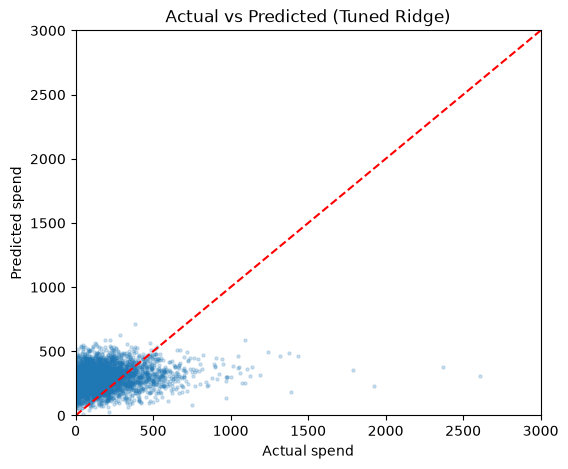

In [20]:
# chart
y_pred = best_ridge_model.predict(x_test)

plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.2, s=5)
plt.plot([0, 3000], [0, 3000], "r--")
plt.xlim(0, 3000)
plt.ylim(0, 3000)
plt.xlabel("Actual spend")
plt.ylabel("Predicted spend")
plt.title("Actual vs Predicted (Tuned Ridge)")
plt.savefig("results/figures/actual_vs_predicted.png", dpi=150)
plt.show()

## Step 12 — Save the Trained Pipeline

In [23]:
final_pipeline = best_ridge_model
joblib.dump(final_pipeline, 'ecommerce_spend_model.pkl')
print("Saved pipeline to: ecommerce_spend_model.pkl")
joblib.dump(final_pipeline, 'ecommerce_spend_model.pkl')
print("Saved pipeline to: ecommerce_spend_model.pkl")

Saved pipeline to: ecommerce_spend_model.pkl
Saved pipeline to: ecommerce_spend_model.pkl


## Step 13 — Save the Trained Pipeline

In [24]:
%%writefile app.py
import streamlit as st
import joblib
import pandas as pd

model = joblib.load('ecommerce_spend_model.pkl')

ct = model.named_steps['preprocessor']
num_cols = list(ct.transformers_[0][2])
cat_cols = list(ct.transformers_[1][2])
ohe = ct.named_transformers_['cat'].named_steps['onehot']

def predict_spend(inputs_dict):
    input_data = pd.DataFrame([inputs_dict])
    prediction = model.predict(input_data)
    return prediction[0]

st.title("Global E-Commerce Spend Prediction (90-Day)")

user_inputs = {}
for col in num_cols:
    user_inputs[col] = st.number_input(col, value=0.0)

for idx, col in enumerate(cat_cols):
    cats = list(ohe.categories_[idx]) if hasattr(ohe, 'categories_') else ['other']
    options = cats if len(cats) > 0 else ['other']
    user_inputs[col] = st.selectbox(col, options)

if st.button("Predict"):
    result = predict_spend(user_inputs)
    st.success(f"Predicted future_customer_spend_90d: {result:.2f}")

Overwriting app.py


## Designing